<a href="https://colab.research.google.com/github/SaraEstilaei/DigiSmart_Assistant/blob/Recommendation%2Fdata_cleaning/Cleaning_data_P2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
!pip install -q gdown

import gdown
import zipfile
import pandas as pd

file_id = '1QOAYptQ9IUngIRw0wk-7I_myCZdDlXsx'
gdown.download(id=file_id, output='data.zip', quiet=False)

with zipfile.ZipFile('data.zip', 'r') as z:
    parquet_file = [f for f in z.namelist() if f.endswith('.parquet')][0]
    comments = pd.read_parquet(z.open(parquet_file))

comments.head()

Downloading...
From (original): https://drive.google.com/uc?id=1QOAYptQ9IUngIRw0wk-7I_myCZdDlXsx
From (redirected): https://drive.google.com/uc?id=1QOAYptQ9IUngIRw0wk-7I_myCZdDlXsx&confirm=t&uuid=21325e81-83d3-4d88-b197-19c977b1788b
To: /content/data.zip
100%|██████████| 373M/373M [00:07<00:00, 51.1MB/s]


,id,product_id,created_date,jalali_year,jalali_month,title,body,body_len,body_persian_ratio,is_short_body,...,disadvantages,n_disadvantages,rate,recommendation_status,is_buyer,likes,dislikes,seller_title,seller_code,true_to_size_rate
0,981586,56962,2016-07-20,1395,4,لطفا موجودش کنید.,بوی خوبی با توجه به قیمت و همه رده هاش داره ام...,161,0.764,False,...,با توجه به قیمت، هیچی!,1,3.4,None,False,7,1,None,None,None
1,989879,62058,2016-07-13,1395,4,عطری ملایم,در ابتدا وقتی استفاده می کنید عطری بسیار ملایم...,194,0.784,False,...,None,0,2.9,None,False,7,0,None,None,None
2,989923,75164,2016-07-14,1395,4,واقعا عالیه,رایحش جوریه که هر سلیقه ای می پسنده. بخرید پشی...,61,0.787,False,...,None,0,5.0,None,False,6,0,None,None,None
3,990155,85612,2016-07-14,1395,4,خیلی ممنون دیجی کالا,واقعا خوش بو و ماندکاری داره دوستانی که این ما...,211,0.806,False,...,None,0,3.0,None,False,3,4,None,None,None
4,990177,87924,2016-07-14,1395,4,لالیک آمیتیس,واقعا از خرید این عطر پشیمونم اولش که بوی بلک ...,221,0.796,False,...,None,0,0.4,None,False,14,6,None,None,None


In [65]:
distribution = pd.DataFrame({
    'Count': comments['recommendation_status'].value_counts(),
    'Percentage': comments['recommendation_status'].value_counts(normalize=True) * 100
})

distribution['Percentage'] = distribution['Percentage'].round(2)

display(distribution)

,Count,Percentage
recommendation_status,,
recommended,4160222,79.12
no_idea,593666,11.29
not_recommended,504472,9.59


In [50]:
import numpy as np

comments['rate_rounded'] = np.floor(comments['rate']).astype('Int64')

In [51]:
pd.crosstab(
    comments['recommendation_status'],
    comments['rate_rounded'],
    margins=True
)

rate_rounded,0,1,2,3,4,5,All
recommendation_status,,,,,,,
no_idea,408,24775,66189,379976,87023,14713,573084
not_recommended,2950,265509,103245,62737,6330,6290,447061
recommended,902,14165,29979,483850,1264007,1941708,3734611
All,4260,304449,199413,926563,1357360,1962711,4754756


In [52]:
pd.crosstab(
    comments['recommendation_status'],
    comments['rate_rounded'],
    normalize='index'
).mul(100).round(2)

rate_rounded,0,1,2,3,4,5
recommendation_status,,,,,,
no_idea,0.07,4.32,11.55,66.30,15.19,2.57
not_recommended,0.66,59.39,23.09,14.03,1.42,1.41
recommended,0.02,0.38,0.80,12.96,33.85,51.99


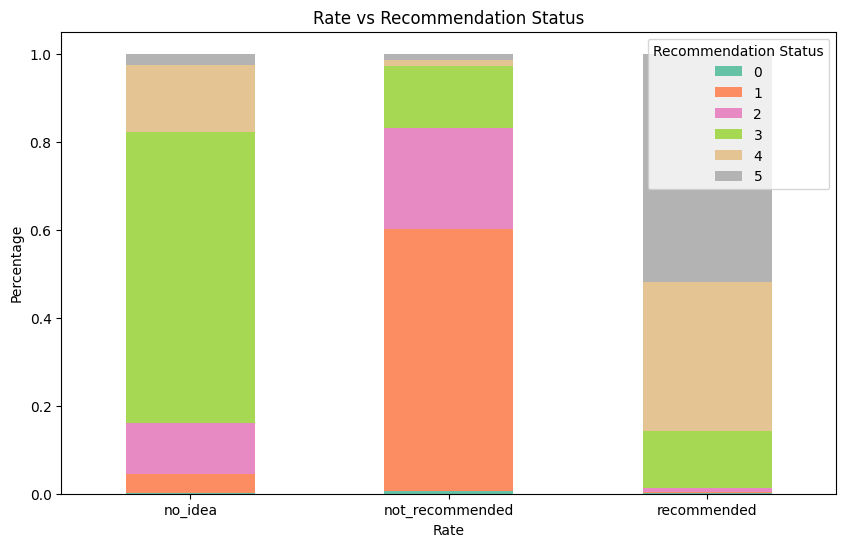

In [53]:
pd.crosstab(
    comments['recommendation_status'],
    comments['rate_rounded'],
    normalize='index'
).plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='Set2'
)

plt.xlabel('Rate')
plt.ylabel('Percentage')
plt.title('Rate vs Recommendation Status')
plt.xticks(rotation=0)
plt.legend(title='Recommendation Status')
plt.show()

In [54]:
comments.loc[
    comments['recommendation_status'].isna(),
    ['likes', 'dislikes']
]

,likes,dislikes
0,7,1
1,7,0
2,6,0
3,3,4
4,14,6
...,...,...
6152126,0,0
6152129,0,0
6152136,0,0
6152137,0,0


In [55]:
comments.loc[
    comments['recommendation_status'].isna(),
    ['likes', 'dislikes']
].describe()

,likes,dislikes
count,893881.000000,893881.000000
mean,0.656639,0.190270
std,2.750719,1.606505
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,437.000000,336.000000


In [56]:
unknown_recommendations = comments[
    comments['recommendation_status'].isna() &
    (
        (comments['likes'] > 100) &
        (comments['dislikes'] < 10)
    )
]
unknown_recommendations

,id,product_id,created_date,jalali_year,jalali_month,title,body,body_len,body_persian_ratio,is_short_body,...,n_disadvantages,rate,recommendation_status,is_buyer,likes,dislikes,seller_title,seller_code,true_to_size_rate,rate_rounded
574,1042115,57296,2016-08-27,1395,6,کیفیت تولید صدا برای هر نت,با سلام.. میخواستم چند نکته رو خدمت عزیزانی که...,1804,0.768,False,...,0,3.80,None,False,108,1,None,None,None,3
2254,1175481,191846,2016-12-29,1395,10,دوربین ps4,لنز هاش از دوربین قدیمی با کیفیت تره و همراهش ...,174,0.787,False,...,0,5.00,None,False,102,6,None,None,None,5
4591,1367178,61695,2017-06-09,1396,3,به کسانی که می گویند ماندگاری ندارد,سلام به دوستانی که می گویند ماندگاری ندارد ( ک...,1184,0.698,False,...,0,1.90,None,False,111,7,None,None,None,1
5198,1412751,204211,2017-07-18,1396,4,توضیح در مورد کاغذ,چون برخی از دوستان از جنس کاغذ انتقاد کردن لاز...,1408,0.788,False,...,1,4.30,None,False,107,4,None,None,None,4
8524,1671114,162738,2018-01-24,1396,11,خیلی بی کیفیته پشیمون میشید,من چند بار گفتم ک خوب نیست و پشیمون میشد اما د...,130,0.785,False,...,1,NaN,None,False,109,9,None,None,None,<NA>
8625,1676848,349586,2018-01-27,1396,11,درجه یک و دو,من اینو از بیرون با قیمت کمی کمتر از دیجی کالا...,382,0.788,False,...,0,3.90,None,False,102,2,None,None,None,3
11430,1847247,443966,2018-05-16,1397,2,دلیل کیفیت پایین این محصول,سلام.دوستان عزیز.اینی که اینجا نوشته پتوی نجات...,505,0.770,False,...,1,3.00,None,False,203,9,None,None,None,3
13832,1984234,443966,2018-07-31,1397,5,عالیه,اینا به این درد میخورن که = نقره ایش برای کویر...,259,0.753,False,...,0,3.00,None,False,156,2,None,None,None,3
17152,2170793,897023,2018-11-01,1397,8,اسم و کیفیت,داداش اسمش اکسو عه نه اگزو 😐 یه گروه کره ایه ک...,68,0.735,False,...,1,2.45,None,False,113,6,None,None,None,2
30021,2814486,775712,2019-05-02,1398,2,بدون رنگ،مناسب پوست چرب,ضدآفتابهای لاروشه پوزای بالاترین امتیازها رو ب...,1898,0.757,False,...,0,5.00,None,False,105,3,None,None,None,5


In [57]:
import numpy as np

idx = unknown_recommendations.index
rate = comments.loc[idx, 'rate']

comments.loc[idx, 'recommendation_status'] = np.select(
    [
        rate <= 2.5,
        (rate > 2.5) & (rate <= 4),
        rate > 4
    ],
    [
        'not_recommended',
        'no_idea',
        'recommended'
    ],
    default=None
)

In [58]:
comments.loc[
    unknown_recommendations.index,
    ['rate', 'likes', 'dislikes', 'recommendation_status']
]

,rate,likes,dislikes,recommendation_status
574,3.80,108,1,no_idea
2254,5.00,102,6,recommended
4591,1.90,111,7,not_recommended
5198,4.30,107,4,recommended
8524,NaN,109,9,None
8625,3.90,102,2,no_idea
11430,3.00,203,9,no_idea
13832,3.00,156,2,no_idea
17152,2.45,113,6,not_recommended
30021,5.00,105,3,recommended


In [59]:
comments = comments.dropna(subset=['recommendation_status']).copy()

In [60]:
comments['recommendation_status'].unique()

array(['recommended', 'no_idea', 'not_recommended'], dtype=object)

In [78]:
comments_for_recommendation = comments.dropna(
    subset=['title', 'body']
)[
    [
        'product_id',
        'rate',
        'created_date',
        'body_persian_ratio',
        'title',
        'body',
        'advantages',
        'disadvantages',
        'recommendation_status',
        'likes',
        'dislikes'
    ]
].copy()

In [79]:
comments_for_recommendation

,product_id,rate,created_date,body_persian_ratio,title,body,advantages,disadvantages,recommendation_status,likes,dislikes
56,134951,4.80,2016-07-19,0.773,قدرتمند و بی ادعا,بعد 4و5 سال استفاده هنوز آخ نگفته و قدرتمند و ...,باطری، قدرت موتور ،تیز بودن,خط زن، عملکرد در زدن موی بلند، ظاهر,recommended,4,2
124,155948,5.00,2016-07-23,0.751,خیلی عالی و قشنگه,آقا اول این موضوع رو بگم که اکانت بنده یه مشکل...,رنگ شفاف که خاصش میکنه | خیلی مدرنه DaulShock 4,عمر باتری کمه ولی توی شارژ شدن سرعتش خوبه,recommended,15,5
128,56498,4.00,2016-07-24,0.779,بهترین,بی شک از بهترین ها برای تابستون هستش مخصوصا ای...,None,None,recommended,2,7
171,57235,3.60,2016-07-27,0.780,ارزش خرید,سلام من خریدم بد نیست. ممنون از دیجیکالا.,None,None,recommended,2,0
184,90109,4.65,2016-07-28,0.784,تجربه و لذت استفاده,وقتی از داخل جعبه درش آوردم واقعا به دلم نشست....,شیک | کاربردی | خودکارهای هدیه کاربردی,None,recommended,11,2
...,...,...,...,...,...,...,...,...,...,...,...
6152193,8609815,5.00,2023-10-18,0.909,بخرید,عالیه بخرید,None,None,recommended,0,0
6152197,2303408,2.00,2023-10-18,0.754,متوسط,جنس متوسطی داره. اما دوخت و رنگ خوبی داره. بوی...,None,None,recommended,0,0
6152200,10821035,5.00,2023-10-18,0.764,جنس و طرح خوب,تازه به دستم رسید و همه چیش همونی بود که توی س...,اندازه درست | طرح مثل عکس | جنس پارچه خیلی خوب,None,recommended,0,0
6152204,8025617,4.00,2023-10-18,0.671,پلیور پائیزان,جنس و کیفیت خوبی داره و مناسب فصل سرماست با قد...,جنس خوب | خوش دوخت | مطابق شکل با اندازه درست,قیمت,recommended,0,0


In [80]:
popular_comments = comments_for_recommendation[
    (comments_for_recommendation['likes'] >= comments_for_recommendation['dislikes']) &
    (comments_for_recommendation['dislikes'] < 10)
].copy()
popular_comments

,product_id,rate,created_date,body_persian_ratio,title,body,advantages,disadvantages,recommendation_status,likes,dislikes
56,134951,4.80,2016-07-19,0.773,قدرتمند و بی ادعا,بعد 4و5 سال استفاده هنوز آخ نگفته و قدرتمند و ...,باطری، قدرت موتور ،تیز بودن,خط زن، عملکرد در زدن موی بلند، ظاهر,recommended,4,2
124,155948,5.00,2016-07-23,0.751,خیلی عالی و قشنگه,آقا اول این موضوع رو بگم که اکانت بنده یه مشکل...,رنگ شفاف که خاصش میکنه | خیلی مدرنه DaulShock 4,عمر باتری کمه ولی توی شارژ شدن سرعتش خوبه,recommended,15,5
171,57235,3.60,2016-07-27,0.780,ارزش خرید,سلام من خریدم بد نیست. ممنون از دیجیکالا.,None,None,recommended,2,0
184,90109,4.65,2016-07-28,0.784,تجربه و لذت استفاده,وقتی از داخل جعبه درش آوردم واقعا به دلم نشست....,شیک | کاربردی | خودکارهای هدیه کاربردی,None,recommended,11,2
185,48536,3.00,2016-07-28,0.721,متوسط,با گوشی z5 خیلی خوب جواب میده . با تبلت ترنسفو...,None,None,no_idea,1,1
...,...,...,...,...,...,...,...,...,...,...,...
6152193,8609815,5.00,2023-10-18,0.909,بخرید,عالیه بخرید,None,None,recommended,0,0
6152197,2303408,2.00,2023-10-18,0.754,متوسط,جنس متوسطی داره. اما دوخت و رنگ خوبی داره. بوی...,None,None,recommended,0,0
6152200,10821035,5.00,2023-10-18,0.764,جنس و طرح خوب,تازه به دستم رسید و همه چیش همونی بود که توی س...,اندازه درست | طرح مثل عکس | جنس پارچه خیلی خوب,None,recommended,0,0
6152204,8025617,4.00,2023-10-18,0.671,پلیور پائیزان,جنس و کیفیت خوبی داره و مناسب فصل سرماست با قد...,جنس خوب | خوش دوخت | مطابق شکل با اندازه درست,قیمت,recommended,0,0


In [81]:
distribution = pd.DataFrame({
    'Count': popular_comments['recommendation_status'].value_counts(),
    'Percentage': popular_comments['recommendation_status'].value_counts(normalize=True) * 100
})

distribution['Percentage'] = distribution['Percentage'].round(2)

display(distribution)

,Count,Percentage
recommendation_status,,
recommended,2177311,79.39
not_recommended,290165,10.58
no_idea,275237,10.04


In [82]:
import pandas as pd
import numpy as np

# تعداد کل نمونه موردنظر
n = 15000

# محاسبه تعداد سهم هر دسته
counts = popular_comments['recommendation_status'].value_counts()

proportions = counts / counts.sum()
raw_quotas = proportions * n

# گرد کردن سهم‌ها به‌گونه‌ای که مجموع دقیقاً 15000 شود
quotas = np.floor(raw_quotas).astype(int)

remaining = n - quotas.sum()

for category in raw_quotas.sort_values(ascending=False).index[:remaining]:
    quotas[category] += 1

# انتخاب بیشترین likes در هر دسته
selected_groups = []

for category, count in quotas.items():
    group = popular_comments[
        popular_comments['recommendation_status'] == category
    ]

    selected = group.nlargest(count, 'likes')
    selected_groups.append(selected)

# دیتافریم نهایی
comments_sample = pd.concat(selected_groups)

# مرتب‌سازی بر اساس تعداد لایک
comments_sample = comments_sample.sort_values(
    by='likes',
    ascending=False
)

print('Sample shape:', comments_sample.shape)

Sample shape: (15000, 11)


In [83]:
distribution_sample = pd.DataFrame({
    'Original %': popular_comments['recommendation_status'].value_counts(normalize=True) * 100,
    'Sample %': comments_sample['recommendation_status'].value_counts(normalize=True) * 100
})

distribution_sample = distribution_sample.round(2)

display(distribution_sample)

,Original %,Sample %
recommendation_status,,
recommended,79.39,79.39
not_recommended,10.58,10.58
no_idea,10.04,10.03


In [84]:
n = 8000

counts = comments_sample['recommendation_status'].value_counts()
raw_quotas = counts / counts.sum() * n

quotas = np.floor(raw_quotas).astype(int)
remaining = n - quotas.sum()

for category in raw_quotas.sort_values(ascending=False).index[:remaining]:
    quotas[category] += 1

selected_groups = []

for category, count in quotas.items():
    group = comments_sample[
        comments_sample['recommendation_status'] == category
    ]

    selected_groups.append(group.nlargest(count, 'likes'))

comments_sample_8000 = pd.concat(selected_groups).sort_values(
    by='likes',
    ascending=False
)

print(comments_sample_8000.shape)

(8000, 11)


In [85]:
display(
    pd.DataFrame({
        'Count': comments_sample_8000['recommendation_status'].value_counts(),
        'Percentage': comments_sample_8000['recommendation_status'].value_counts(normalize=True) * 100
    }).round(2)
)

,Count,Percentage
recommendation_status,,
recommended,6351,79.39
not_recommended,847,10.59
no_idea,802,10.02


In [86]:
comments_sample.to_parquet(
    'comments_sample_15000.parquet',
    index=False
)

comments_sample_8000.to_parquet(
    'comments_sample_8000.parquet',
    index=False
)

from google.colab import files

files.download('comments_sample_15000.parquet')
files.download('comments_sample_8000.parquet')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>